In [1]:
"ॐ कृष्णाय वासुदेवाय हरये परमात्मने। प्रणतः क्लेशनाशाय गोविंदाय नमो नमः॥"

'ॐ कृष्णाय वासुदेवाय हरये परमात्मने। प्रणतः क्लेशनाशाय गोविंदाय नमो नमः॥'

In [2]:
import sklearn
print(sklearn.__version__)

1.6.1


In [ ]:
!python -m venv myenv

Error: Command '['/content/myenv/bin/python3', '-m', 'ensurepip', '--upgrade', '--default-pip']' returned non-zero exit status 1.


In [ ]:
!curl -sS https://bootstrap.pypa.io/get-pip.py -o get-pip.py
!/content/myenv/bin/python get-pip.py
!rm get-pip.py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 14.3 MB/s  0:00:00


In [ ]:
!/content/myenv/bin/python -m pip install pandas numpy scikit-learn xgboost

  Using cached pandas-3.1.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (18 kB)
  Using cached scikit_learn-1.9.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached xgboost-3.4.1-py3-none-manylinux_2_28_x86_64.whl.metadata (2.0 kB)
  Using cached python_dateutil-3.0.0-py2.py3-none-any.whl.metadata (8.2 kB)
  Using cached scipy-1.18.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached pandas-3.1.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (12.0 MB)
Using cached scikit_learn-1.9.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (9.1 MB)
Using cached xgboost-3.4.1-py3-none-manylinux_2_28_x86_64.whl (57.6 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Usi

In [ ]:
import pandas as pd,numpy as np
from pathlib import Path

In [ ]:
data_path= Path("loan_approval_dataset.csv")
print("dataset exist",data_path.exists())

dataset exist True


In [ ]:
df= pd.read_csv("loan_approval_dataset.csv")

In [ ]:
df.shape, df.columns.tolist()

((4269, 13),
 ['loan_id',
  ' no_of_dependents',
  ' education',
  ' self_employed',
  ' income_annum',
  ' loan_amount',
  ' loan_term',
  ' cibil_score',
  ' residential_assets_value',
  ' commercial_assets_value',
  ' luxury_assets_value',
  ' bank_asset_value',
  ' loan_status'])

In [ ]:
# removing spaces from col name
df.columns= df.columns.str.strip()

In [ ]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [ ]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


# EDA

In [ ]:
import matplotlib.pyplot as plt, seaborn as sns
%matplotlib inline

In [ ]:
df.columns.to_list()

['loan_id',
 'no_of_dependents',
 'education',
 'self_employed',
 'income_annum',
 'loan_amount',
 'loan_term',
 'cibil_score',
 'residential_assets_value',
 'commercial_assets_value',
 'luxury_assets_value',
 'bank_asset_value',
 'loan_status']

using target col: loan_status


,count
loan_status,
Approved,2656
Rejected,1613


<Axes: xlabel='loan_status', ylabel='count'>

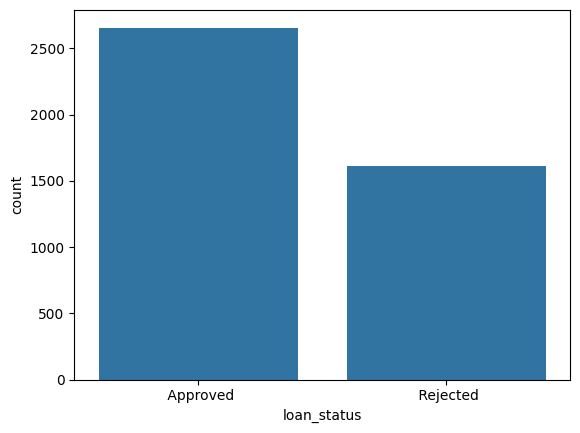

In [ ]:
target_col="loan_status"
print("using target col:",target_col)

display(df[target_col].value_counts(dropna=False))
sns.countplot(x=target_col,data=df)

In [ ]:
2656/4269
# approx 62% loan gets approved

0.622159756383228

In [ ]:
# checking for null value
df.isna().sum().sort_values(ascending=False)

,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


In [ ]:
# dropping id col
df=df.drop(columns=["loan_id"],axis= 1)

In [ ]:
df_clf = df.dropna(subset=[target_col]).copy()

In [ ]:
X= df_clf.drop(columns=[target_col],axis=1)
Y= df_clf[target_col].copy()

### Feature Types

In [ ]:
cat_cols = X.select_dtypes(include=['object','category']).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

In [ ]:
print(cat_cols)
print(num_cols)

['education', 'self_employed']
['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


### preprocessing pipeline

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# pipeline is sequential, impute first then scale

In [ ]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [ ]:
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
], remainder='drop')

# Stage-1 : Classification baseline

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [ ]:
unique_vals = sorted(Y.unique())
unique_vals

[' Approved', ' Rejected']

In [ ]:
y = df_clf[target_col].astype(str).str.strip().str.lower()


In [ ]:
y = (y == 'approved').astype(int)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train/test sizes:", X_train.shape, X_test.shape)

Train/test sizes: (3415, 11) (854, 11)


# Fit RF baseline pipelines

In [ ]:
rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('rf', RandomForestClassifier(random_state=2, oob_score=True))])

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
param_grid = {
    'rf__n_estimators': [100, 200, 300, 400],
    'rf__max_depth': [None, 4, 8, 10],
    'rf__max_features': ['sqrt', None]
}

In [ ]:
grid = GridSearchCV(rf_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['no_of_dependents',
                                                                          'income_annum',
                                                                          'loan_amount',
                                                                          'loan_term',
                                                                          'cibil_score',
                                                                          'residential_assets_value',
                                                                          'commercial_assets_value',
                                                                          'luxury_assets_value',
                                                                          'bank_asse...
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['education',
                                                                          'self_employed'])])),
                                       ('rf',
                                        RandomForestClassifier(oob_score=True,
                                                               random_state=2))]),
             n_jobs=-1,
             param_grid={'rf__max_depth': [None, 4, 8, 10],
                         'rf__max_features': ['sqrt', None],
                         'rf__n_estimators': [100, 200, 300, 400]},
             scoring='f1')

In [ ]:
print("Best params (RF):", grid.best_params_)
best_clf = grid.best_estimator_
y_pred_best = best_clf.predict(X_test)
print(classification_report(y_test, y_pred_best))

Best params (RF): {'rf__max_depth': 10, 'rf__max_features': None, 'rf__n_estimators': 400}
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       323
           1       0.98      1.00      0.99       531

    accuracy                           0.99       854
   macro avg       0.99      0.98      0.98       854
weighted avg       0.99      0.99      0.99       854



In [ ]:
rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('rf', RandomForestClassifier(n_estimators=400, max_depth=10,
                                                            max_features=None,random_state=2,
                                                            oob_score=True))])

In [ ]:
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)
print('Random Forest:')
print(classification_report(y_test, y_pred_rf))
print('RF OOB score (if available):', getattr(rf_pipeline.named_steps['rf'],'oob_score_', None))

Random Forest:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       323
           1       0.98      1.00      0.99       531

    accuracy                           0.99       854
   macro avg       0.99      0.98      0.98       854
weighted avg       0.99      0.99      0.99       854

RF OOB score (if available): 0.9818448023426062


In [ ]:
rf_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['no_of_dependents',
                                                   'income_annum',
                                                   'loan_amount', 'loan_term',
                                                   'cibil_score',
                                                   'residential_assets_value',
                                                   'commercial_assets_value',
                                                   'luxury_assets_value',
                                                   'bank_asset_value']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['education',
                                                   'self_employed'])])),
                ('rf',
                 RandomForestClassifier(max_depth=10, max_features=None,
                                        n_estimators=400, oob_score=True,
                                        random_state=2))])

In [ ]:
getattr(rf_pipeline.named_steps['rf'],'feature_importances_', None)

array([2.80795214e-03, 2.55243742e-02, 3.53461310e-02, 8.68853632e-02,
       8.25637730e-01, 5.27227505e-03, 6.14868420e-03, 8.45760683e-03,
       2.52914212e-03, 3.23754983e-04, 2.85592277e-04, 3.61616034e-04,
       4.19777707e-04])

# Stage 2

In [ ]:
df["loan_status"].unique()

array([' Approved', ' Rejected'], dtype=object)

In [ ]:
df['loan_status'] = df['loan_status'].astype(str).str.strip().str.lower()

In [ ]:
df['loan_status'].unique()

array(['approved', 'rejected'], dtype=object)

In [ ]:
approved_df = df[df["loan_status"] == "approved"].copy()

In [ ]:
approved_df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,approved
6,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,approved
8,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,approved
10,4,Graduate,Yes,2900000,11200000,2,547,8100000,4700000,9500000,3100000,approved
13,2,Graduate,Yes,9100000,31500000,14,679,10800000,16600000,20900000,5000000,approved


In [ ]:
reg_target = "loan_amount"
reg_df = approved_df.dropna(subset=[reg_target]).copy()

In [ ]:
X_reg = reg_df.drop(columns=[reg_target])
y_reg = reg_df[reg_target]

In [ ]:
num_cols_reg = X_reg.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols_reg = X_reg.select_dtypes(include=['object']).columns.tolist()

In [ ]:
print("Regression Numerical:", num_cols_reg)
print("Regression Categorical:", cat_cols_reg)

Regression Numerical: ['no_of_dependents', 'income_annum', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Regression Categorical: ['education', 'self_employed', 'loan_status']


In [ ]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

In [ ]:
reg_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols_reg),
        ("cat", OneHotEncoder(handle_unknown='ignore'), cat_cols_reg)
    ],
remainder='drop')

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
reg_pipe = Pipeline(steps=[
    ('preprocessor', reg_preprocessor),
    ('model', RandomForestRegressor(random_state=42, oob_score=True))
])

In [ ]:
param_grid_reg = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5, 10]
}

In [ ]:
grid_reg = GridSearchCV(
    reg_pipe,
    param_grid_reg,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

In [ ]:
grid_reg.fit(Xr_train, yr_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['no_of_dependents',
                                                                          'income_annum',
                                                                          'loan_term',
                                                                          'cibil_score',
                                                                          'residential_assets_value',
                                                                          'commercial_assets_value',
                                                                          'luxury_assets_value',
                                                                          'bank_asset_value']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['education',
                                                                          'self_employed',
                                                                          'loan_status'])])),
                                       ('model',
                                        RandomForestRegressor(oob_score=True,
                                                              random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 5, 10],
                         'model__min_samples_split': [2, 5, 10],
                         'model__n_estimators': [100, 200, 300]},
             scoring='r2')

In [ ]:
print("Best Regression Params:", grid_reg.best_params_)
best_reg = grid_reg.best_estimator_

Best Regression Params: {'model__max_depth': 5, 'model__min_samples_split': 10, 'model__n_estimators': 300}


In [ ]:
grid_reg.best_score_

np.float64(0.8678578718038459)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
reg_pipe = Pipeline(steps=[
    ('preprocessor', reg_preprocessor),
    ('model', RandomForestRegressor(max_depth=5, min_samples_split=10,n_estimators=300, random_state=42, oob_score=True))
])

In [ ]:
reg_pipe.fit(Xr_train, yr_train)
yr_pred = reg_pipe.predict(Xr_test)
print("Regression metrics on approved applicants:")
print("RMSE:", mean_squared_error(yr_test, yr_pred))
print("MAE:", mean_absolute_error(yr_test, yr_pred))
print("R2:", r2_score(yr_test, yr_pred))

Regression metrics on approved applicants:
RMSE: 10794004746004.68
MAE: 2451526.9067810844
R2: 0.8744177380038414


In [ ]:
import joblib

In [ ]:
import os
os.makedirs('./models', exist_ok=True)
joblib.dump(rf_pipeline, './models/stage_1_rf_classifier_pipeline.pkl')
joblib.dump(reg_pipe, './models/stage_2_rf_regression_pipeline.pkl')

['./models/stage_2_rf_regression_pipeline.pkl']

In [ ]:
clf = joblib.load('./models/stage_1_rf_classifier_pipeline.pkl')
reg = joblib.load('./models/stage_2_rf_regression_pipeline.pkl')

In [ ]:
def two_stage_predict(applicant_df):
    out = {}

    # Stage 1
    approve = clf.predict(applicant_df)[0]
    print(approve)
    out['loan_status'] = int(approve)

    if approve == 1:
        # ADD predicted loan_status column to input
        applicant_df_reg = applicant_df.copy()
        applicant_df_reg['loan_status'] = 'approved'

        # Stage 2 prediction
        pred = reg.predict(applicant_df_reg)[0]
        out['regression_prediction'] = float(pred)
    else:
        print("Not approved")

    return out

In [ ]:
X_test.iloc[[0]]

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
2856,3,Not Graduate,Yes,8300000,31400000,6,674,1000000,1600000,17200000,6100000


In [ ]:
example_row = X_test.iloc[[0]]

In [ ]:
example_row.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1 entries, 2856 to 2856
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   no_of_dependents          1 non-null      int64 
 1   education                 1 non-null      object
 2   self_employed             1 non-null      object
 3   income_annum              1 non-null      int64 
 4   loan_amount               1 non-null      int64 
 5   loan_term                 1 non-null      int64 
 6   cibil_score               1 non-null      int64 
 7   residential_assets_value  1 non-null      int64 
 8   commercial_assets_value   1 non-null      int64 
 9   luxury_assets_value       1 non-null      int64 
 10  bank_asset_value          1 non-null      int64 
dtypes: int64(9), object(2)
memory usage: 96.0+ bytes


In [ ]:
user_input = {
    "no_of_dependents": int(input("No. of Dependents: ")),
    "education": input("Education (Graduate/Not Graduate): "),
    "self_employed": input("Self Employed (Yes/No): "),
    "income_annum": float(input("Annual Income: ")),
    "loan_amount": float(input("Loan Amount Requested: ")),
    "loan_term": int(input("Loan Term (in years): ")),
    "cibil_score": int(input("CIBIL Score: ")),
    "residential_assets_value": float(input("Residential Assets Value: ")),
    "commercial_assets_value": float(input("Commercial Assets Value: ")),
    "luxury_assets_value": float(input("Luxury Assets Value: ")),
    "bank_asset_value": float(input("Bank Asset Value: "))
}

applicant_df = pd.DataFrame([user_input])

result = two_stage_predict(applicant_df)

print("Final Output:")
print(result)

No. of Dependents: 5
Education (Graduate/Not Graduate): Graduate
Self Employed (Yes/No): Yes
Annual Income: 0
Loan Amount Requested: 500000
Loan Term (in years): 5
CIBIL Score: 500
Residential Assets Value: 0
Commercial Assets Value: 9
Luxury Assets Value: 0
Bank Asset Value: 0
0
Not approved
Final Output:
{'loan_status': 0}


In [ ]:
try:
    print("FEATURE IMPORTANCES:")
    for pipeline, model_key in [(clf, "rf"), (reg, "model")]:

        # 1. Extract the actual model step
        model_step = pipeline.named_steps[model_key]

        # 2. Get feature names from the PREVIOUS step (or the pipeline input if no resizing happened)
        # If your pipeline has a preprocessor step (e.g., named 'preprocessor'):
        if 'preprocessor' in pipeline.named_steps:
            feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
        else:
            # Fallback to the pipeline's overall input names if it didn't change column count
            feature_names = pipeline.feature_names_in_

        # 3. Extract the weights
        importances = model_step.feature_importances_

        # 4. Zip and print
        for col, score in zip(feature_names, importances):
            print(f"{col:30s} : {score:.4f}")

        print("===" * 10)

except AttributeError as e:
    print(f"Extraction failed. Specific error: {e}")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

FEATURE IMPORTANCES:
num__no_of_dependents          : 0.0028
num__income_annum              : 0.0255
num__loan_amount               : 0.0353
num__loan_term                 : 0.0869
num__cibil_score               : 0.8256
num__residential_assets_value  : 0.0053
num__commercial_assets_value   : 0.0061
num__luxury_assets_value       : 0.0085
num__bank_asset_value          : 0.0025
cat__education_ Graduate       : 0.0003
cat__education_ Not Graduate   : 0.0003
cat__self_employed_ No         : 0.0004
cat__self_employed_ Yes        : 0.0004
num__no_of_dependents          : 0.0007
num__income_annum              : 0.9792
num__loan_term                 : 0.0027
num__cibil_score               : 0.0050
num__residential_assets_value  : 0.0026
num__commercial_assets_value   : 0.0040
num__luxury_assets_value       : 0.0031
num__bank_asset_value          : 0.0026
cat__education_ Graduate       : 0.0000
cat__education_ Not Graduate   : 0.0000
cat__self_employed_ No         : 0.0001
cat__self_employed_

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil

project = "/content/drive/MyDrive/LoanProject"
os.makedirs(project + "/models", exist_ok=True)

# Dataset aur Python file copy karo
shutil.copy(
    "/content/loan_approval_dataset.csv",
    project + "/loan_approval_dataset.csv"
)

shutil.copy(
    "/content/loan_model.py",
    project + "/loan_model.py"
)

# Existing models folder copy karo, agar usmein files hain
if os.path.isdir("/content/models"):
    shutil.copytree(
        "/content/models",
        project + "/models",
        dirs_exist_ok=True
    )
